# SurfaceGuard AI — Industrial Surface Anomaly Segmentation
**DL & GenAI Project · T3 2026 · Final submission notebook (Model 1: U-Net built from scratch)**

This notebook is a single, top-to-bottom pipeline: it loads the data, trains a **U-Net with randomly initialised weights (no pretrained encoder)**, tunes the post-processing on a held-out validation set, and writes `submission.csv` in the exact format of `sample_submission.csv`.

| # | Stage | What happens |
|---|---|---|
| 1 | Setup | Config, seeds, optional Weights & Biases tracking |
| 2 | Data | Locate files, read `train.csv`, RLE decode/encode (with round-trip test) |
| 3 | Split | Stratified train/validation split **by image** |
| 4 | Cache + augment | Decode everything once into RAM; GPU augmentations |
| 5 | Model | Residual U-Net, trained from scratch |
| 6 | Training | BCE + Dice loss, AdamW + OneCycle, AMP, best checkpoint by *competition-style* score |
| 7 | Post-processing | Per-class probability threshold and minimum-area tuned on validation, flip TTA |
| 8 | Error analysis | Per-class numbers and worst-case examples (for the report) |
| 9 | Submission | Predict the 3000 test images, RLE-encode, validate format |

**About the metric.** The leaderboard score is `0.7·Dice(foreground) + 0.2·FalsePositiveScore + 0.1·EmptyPredictionAccuracy`, computed over every `image × defect_type` pair.
Only ~16 % of pairs contain a defect, so a model that predicts *nothing* already earns ~0.3 from the last two terms — **the real work is the 70 % Dice term**, i.e. finding the defects *and* outlining them accurately, while staying quiet on clean pairs. The exact false-positive formula is not published, so the local metric below is a conservative proxy; the Kaggle leaderboard is the final judge.

## 1 · Setup

In [1]:
import os, glob, time, random, json, csv
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from concurrent.futures import ThreadPoolExecutor

# ----------------------------- configuration -----------------------------
CFG = dict(
    seed        = 42,
    val_frac    = 0.20,     # share of images held out for validation
    crop_w      = 320,      # training crops are 128 x crop_w (inference uses the full 128 x 800)
    batch_size  = 32,
    epochs      = 30,
    lr          = 2e-3,     # peak LR of the OneCycle schedule
    weight_decay= 1e-4,
    base        = 24,       # U-Net width: channels = base * [1, 2, 4, 8, 16]
    time_limit_min = 150,   # safety stop (best checkpoint is already saved)
    debug       = False,    # True = tiny smoke test (400 images, 1 epoch) to check the notebook runs
)
H, W = 128, 800                                   # every image is 800 wide x 128 high
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
INPUT_ROOT, WORK_DIR = "/kaggle/input", "/kaggle/working"
dev = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = dev == "cuda"

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["seed"])
torch.backends.cudnn.benchmark = True
if CFG["debug"]: CFG.update(epochs=1)
print(f"device={dev} | GPUs={torch.cuda.device_count()} | torch {torch.__version__}")

device=cpu | GPUs=0 | torch 2.11.0+cpu


**Experiment tracking (Weights & Biases).** The project guidelines require valid W&B runs. The API key is read from **Kaggle Secrets** (`Add-ons → Secrets → label: WANDB_API_KEY`), so no key ever appears in the notebook or on GitHub. If the secret is missing, the notebook simply runs without logging.

In [2]:
RUN = None
try:
    import wandb
    from kaggle_secrets import UserSecretsClient
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    RUN = wandb.init(project="24f3002508-t32026", name="model1-unet-scratch", config=CFG)
    print("W&B run:", RUN.url)
except Exception as e:
    print("W&B logging disabled ->", type(e).__name__)

def log(d):
    if RUN is not None: RUN.log(d)

W&B logging disabled -> BackendError


## 2 · Data and RLE utilities

In [3]:
def find_one(pattern, root=INPUT_ROOT):
    hits = glob.glob(f"{root}/**/{pattern}", recursive=True)
    assert hits, f"{pattern} not found under {root} - did you add the competition data to the notebook?"
    return hits[0]

TRAIN_CSV, SAMPLE_SUB = find_one("train.csv"), find_one("sample_submission.csv")
DATA_ROOT = os.path.dirname(TRAIN_CSV)

def index_images(folder):
    paths = glob.glob(os.path.join(folder, "**", "*.jpg"), recursive=True)
    return {os.path.splitext(os.path.basename(p))[0]: p for p in paths}

TRAIN_PATHS = index_images(os.path.join(DATA_ROOT, "train"))
TEST_PATHS  = index_images(os.path.join(DATA_ROOT, "test"))
print(DATA_ROOT, "| train images:", len(TRAIN_PATHS), "| test images:", len(TEST_PATHS))

df = pd.read_csv(TRAIN_CSV, keep_default_na=False)           # empty RLE stays '' instead of NaN
assert (df.width == W).all() and (df.height == H).all()
df["has_defect"] = df.mask_rle.str.strip() != ""
print(df.shape, "| unique images:", df.image_id.nunique())
display(df.groupby("defect_type").has_defect.agg(images_with_defect="sum", fraction="mean").round(3))

/kaggle/input/competitions/industrial-surface-defect-detection/public | train images: 11393 | test images: 3000
(45572, 6) | unique images: 11393


,images_with_defect,fraction
defect_type,,
defect_a,1081,0.095
defect_b,313,0.027
defect_c,4100,0.360
defect_d,1707,0.150


**RLE format.** `start length start length …`, **1-indexed**, pixels counted **down each column first** (column-major). Pixel `(row, col)` therefore sits at position `col·128 + row + 1`. The round-trip test below checks `encode(decode(x)) == x` on *every* non-empty training mask — if this passes, the submission encoding is correct.

In [4]:
def rle_decode(rle, shape=(H, W)):
    # RLE string -> binary mask (H, W), uint8
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        s = np.array(rle.split(), dtype=np.int64)
        for st, ln in zip(s[0::2] - 1, s[1::2]):
            flat[st:st + ln] = 1
    return flat.reshape(shape[1], shape[0]).T            # column-major

def rle_encode(mask):
    # binary mask (H, W) -> RLE string ('' if empty)
    px = np.concatenate([[0], np.asarray(mask).T.flatten(), [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))

nonempty = df[df.has_defect].mask_rle.tolist()
bad = sum(rle_encode(rle_decode(r)) != r.strip() for r in nonempty)
print(f"RLE round-trip mismatches: {bad} / {len(nonempty)}")
assert bad == 0 and rle_encode(np.zeros((H, W), np.uint8)) == ""

RLE round-trip mismatches: 0 / 7201


## 3 · Train / validation split
One row per **image** (with its four RLE strings). The split is made **by image** — never by `image × defect` row, which would leak the same picture into both sets — and is stratified on the *pattern* of defects present (e.g. `0101` = defects b and d), so rare classes and multi-defect images appear in both sets in the same proportion.

In [5]:
table = (df.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS].fillna("").reset_index())
for d in DEFECTS:
    table["has_" + d[-1]] = (table[d].str.strip() != "").astype(int)
table["pattern"] = table[[f"has_{d[-1]}" for d in DEFECTS]].astype(str).agg("".join, axis=1)

if CFG["debug"]:
    table = table.sample(400, random_state=CFG["seed"]).reset_index(drop=True)

vc = table.pattern.value_counts()
table["strat"] = table.pattern.where(table.pattern.map(vc) >= 2, vc.index[0])   # fold singleton patterns into the biggest one
train_tab, val_tab = train_test_split(table, test_size=CFG["val_frac"], stratify=table.strat, random_state=CFG["seed"])
train_tab, val_tab = train_tab.reset_index(drop=True), val_tab.reset_index(drop=True)
assert set(train_tab.image_id).isdisjoint(val_tab.image_id)

print("train images:", len(train_tab), "| val images:", len(val_tab))
display(pd.DataFrame({"train": [train_tab[f"has_{d[-1]}"].mean() for d in DEFECTS],
                      "val":   [val_tab[f"has_{d[-1]}"].mean() for d in DEFECTS]}, index=DEFECTS).round(4))
table.assign(is_val=table.image_id.isin(val_tab.image_id).astype(int))[["image_id", "pattern", "is_val"]] \
     .to_csv(f"{WORK_DIR}/split.csv", index=False)       # reuse this exact split for the pretrained / third model

train images: 9114 | val images: 2279


,train,val
defect_a,0.0949,0.0948
defect_b,0.0274,0.0276
defect_c,0.3599,0.3598
defect_d,0.1498,0.1501


## 4 · Cache the data in RAM and define GPU augmentations
The images are small (128×800), so the whole dataset fits in memory as `uint8`. Decoding everything **once** removes the DataLoader bottleneck entirely, and augmentations then run on the GPU on whole batches.

**Augmentations** (training only, applied identically to image and mask): random **width crop** of 128×320 (3× cheaper per step and a different view every epoch — the network is fully convolutional, so it is evaluated on the full 128×800 image), random horizontal / vertical **flips**, and random **brightness / contrast** jitter.

In [6]:
def read_rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    assert img is not None, path
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img if img.shape[:2] == (H, W) else cv2.resize(img, (W, H))

def build_cache(tab):
    ids, rles = tab.image_id.tolist(), tab[DEFECTS].values
    def one(i):
        return read_rgb(TRAIN_PATHS[ids[i]]).transpose(2, 0, 1), np.stack([rle_decode(r) for r in rles[i]])
    with ThreadPoolExecutor(8) as ex:
        out = list(ex.map(one, range(len(ids))))
    return torch.from_numpy(np.stack([o[0] for o in out])), torch.from_numpy(np.stack([o[1] for o in out]))

t0 = time.time()
Xtr, Ytr = build_cache(train_tab)      # uint8 (N,3,H,W), uint8 (N,4,H,W)
Xva, Yva = build_cache(val_tab)
print(f"cached train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} in {time.time()-t0:.0f}s")

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def prep(x_uint8):
    # uint8 (B,3,H,W) on CPU -> normalised float on GPU
    x = x_uint8.to(dev, non_blocking=True).float().div_(255)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def get_batch(X, Y, idx, train):
    x = X[idx].to(dev, non_blocking=True).float().div_(255)
    y = Y[idx].to(dev, non_blocking=True).float()
    if train:
        B = x.size(0)
        s = random.randint(0, W - CFG["crop_w"])                         # width crop
        x, y = x[..., s:s + CFG["crop_w"]], y[..., s:s + CFG["crop_w"]]
        for dim in (3, 2):                                               # per-sample h / v flips
            f = (torch.rand(B, device=dev) < 0.5).view(-1, 1, 1, 1)
            x, y = torch.where(f, x.flip(dim), x), torch.where(f, y.flip(dim), y)
        c = 1 + (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.4         # contrast  +-20 %
        b = (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.2             # brightness +-0.1
        x = ((x - 0.5) * c + 0.5 + b).clamp(0, 1)
    x = ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)
    return x, y.contiguous()

cached train (9114, 3, 128, 800) | val (2279, 3, 128, 800) in 13s


**Sanity check — do the masks sit on real defects?** (If an overlay looks shifted or transposed, the RLE decoding would be wrong.)

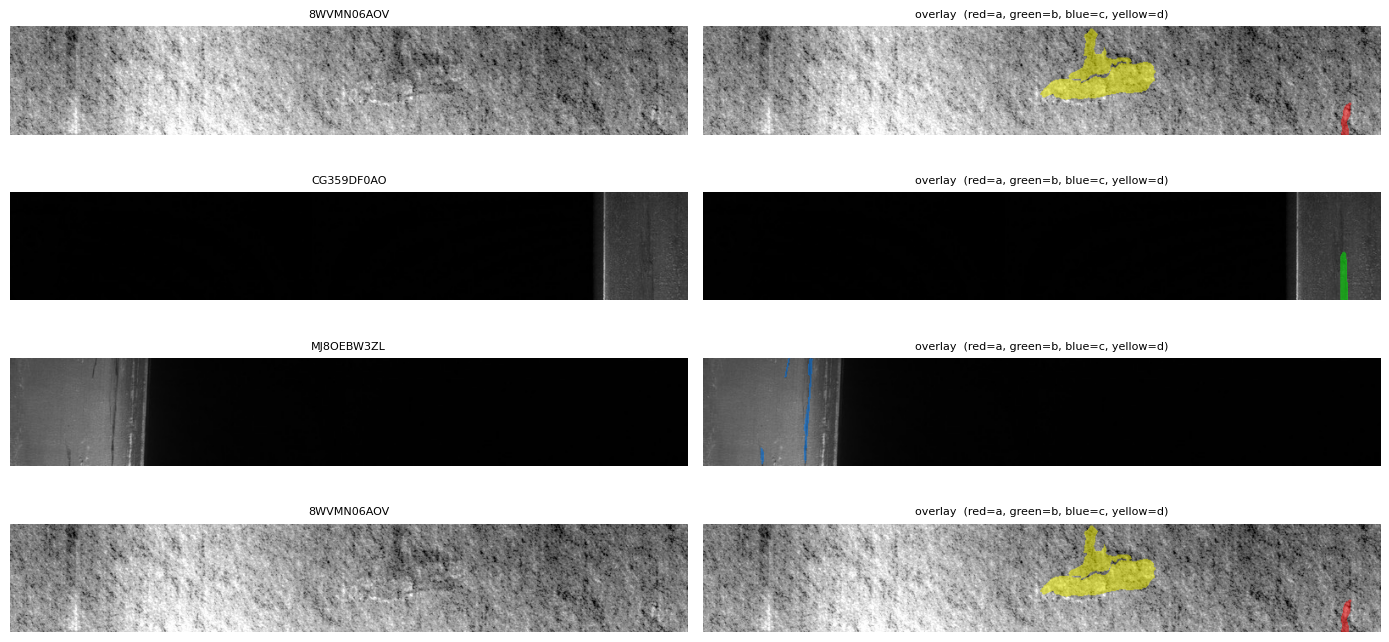

In [7]:
COLORS = {"defect_a": (255, 0, 0), "defect_b": (0, 255, 0), "defect_c": (0, 128, 255), "defect_d": (255, 255, 0)}
def overlay(img, mask4, alpha=0.5):
    out = img.astype(np.float32).copy()
    for k, d in enumerate(DEFECTS):
        m = mask4[k].astype(bool)
        out[m] = (1 - alpha) * out[m] + alpha * np.array(COLORS[d], np.float32)
    return out.astype(np.uint8)

picks = [int(np.where(Yva[:, k].flatten(1).sum(1).numpy() > 0)[0][0]) for k in range(4)]
fig, ax = plt.subplots(4, 2, figsize=(14, 7))
for r, i in enumerate(picks):
    img = Xva[i].numpy().transpose(1, 2, 0)
    ax[r, 0].imshow(img); ax[r, 0].set_title(f"{val_tab.image_id[i]}", fontsize=8)
    ax[r, 1].imshow(overlay(img, Yva[i].numpy())); ax[r, 1].set_title(f"overlay  (red=a, green=b, blue=c, yellow=d)", fontsize=8)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()

## 5 · Model 1 — Residual U-Net, trained from scratch
A classic encoder–decoder with skip connections, **no pretrained weights anywhere**:

```
 input 3x128xW
   │  enc0 [24]  ──────────────────────────────────────────────┐ skip
   ▼ pool                                                       │
   │  enc1 [48]  ───────────────────────────────────────┐ skip │
   ▼ pool                                                │      │
   │  enc2 [96]  ────────────────────────────────┐ skip  │      │
   ▼ pool                                         │       │      │
   │  enc3 [192] ─────────────────────────┐ skip  │       │      │
   ▼ pool                                  │       │       │      │
   │  bottleneck [384] (dropout)           │       │       │      │
   ▲ up + concat → dec3 [192] ◄────────────┘       │       │      │
   ▲ up + concat → dec2 [96]  ◄────────────────────┘       │      │
   ▲ up + concat → dec1 [48]  ◄────────────────────────────┘      │
   ▲ up + concat → dec0 [24]  ◄───────────────────────────────────┘
   │  1x1 conv → 4 logits (one channel per defect type)
```
* Each block is two `3×3 conv → BatchNorm → ReLU` layers with a **residual shortcut**, which makes a from-scratch network train faster and more stably.
* **Four sigmoid output channels** (multi-label) instead of a softmax: an image can contain several defect types, and the masks never need to be mutually exclusive.
* Width/height are divisible by 16 (128 and 800 → 8 and 50 at the bottleneck), so all skip connections line up without padding tricks.

In [8]:
class ResBlock(nn.Module):
    def __init__(self, i, o, drop=0.0):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Dropout2d(drop) if drop > 0 else nn.Identity(),
            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o))
        self.skip = nn.Identity() if i == o else nn.Sequential(nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o))
        self.act = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.act(self.body(x) + self.skip(x))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=4, base=24, depth=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(depth + 1)]
        self.enc  = nn.ModuleList([ResBlock(in_ch, ch[0])] + [ResBlock(ch[i], ch[i + 1], drop=0.1 if i == depth - 1 else 0) for i in range(depth)])
        self.pool = nn.MaxPool2d(2)
        self.up   = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, 2) for i in reversed(range(depth))])
        self.dec  = nn.ModuleList([ResBlock(2 * ch[i], ch[i]) for i in reversed(range(depth))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
    def forward(self, x):
        x = self.enc[0](x); skips = [x]
        for e in self.enc[1:]:
            x = e(self.pool(x)); skips.append(x)
        x = skips.pop()                                   # bottleneck
        for up, dec in zip(self.up, self.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return self.head(x)                               # raw logits (B,4,H,W)

model = UNet(base=CFG["base"]).to(dev).to(memory_format=torch.channels_last)
print(f"parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")
with torch.no_grad():                                      # forward-pass shape test
    out = model.eval()(torch.randn(2, 3, H, W, device=dev).contiguous(memory_format=torch.channels_last))
assert out.shape == (2, 4, H, W); print("forward pass OK:", tuple(out.shape))
if torch.cuda.device_count() > 1: model = nn.DataParallel(model)

parameters: 4.57 M
forward pass OK: (2, 4, 128, 800)


## 6 · Loss, metric and training
**Loss = BCE + soft Dice.** Defect pixels are a tiny fraction of all pixels, so plain BCE alone lets the network get away with predicting “nothing”. The Dice term directly optimises the overlap that the competition rewards; BCE keeps gradients smooth and well-behaved.

**Local metric.** `competition_score` re-implements the three-part score from raw per-pair statistics (intersection, predicted area, true area). The checkpoint with the best *score* (not the lowest loss) is kept, since that is what the leaderboard measures.

In [9]:
bce = nn.BCEWithLogitsLoss()
def criterion(logits, y, eps=1.0):
    p = torch.sigmoid(logits)
    inter, den = (p * y).sum((0, 2, 3)), p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    dice_loss = 1 - ((2 * inter + eps) / (den + eps)).mean()          # one Dice per defect channel, averaged
    return bce(logits, y) + dice_loss

def competition_score(inter, psum, gsum):
    # inputs: arrays (N_images, 4) of intersection / predicted pixels / true pixels per image x defect pair.
    # 0.7*Dice on pairs that HAVE a defect + 0.2*FP score + 0.1*empty accuracy on pairs that do NOT.
    pos = gsum > 0; neg = ~pos
    fg = (2 * inter[pos] / (psum[pos] + gsum[pos])).mean()            # empty prediction on a defect pair -> Dice 0
    clean = (psum[neg] == 0).mean()                                   # share of defect-free pairs left empty
    return 0.7 * fg + 0.2 * clean + 0.1 * clean, dict(fg_dice=fg, clean_rate=clean)

def autocast(): return torch.autocast(device_type=dev, dtype=torch.float16, enabled=use_amp)

@torch.no_grad()
def evaluate(model, X, Y, bs=64):
    model.eval(); tot, I, P, G = 0.0, [], [], []
    for s in range(0, len(X), bs):
        idx = torch.arange(s, min(s + bs, len(X)))
        x, y = get_batch(X, Y, idx, train=False)
        with autocast(): logits = model(x)
        logits = logits.float(); tot += criterion(logits, y).item() * len(idx)
        m = (logits > 0).float()                                      # logit>0  <=>  prob>0.5
        I.append((m * y).sum((2, 3)).cpu()); P.append(m.sum((2, 3)).cpu()); G.append(y.sum((2, 3)).cpu())
    I, P, G = (torch.cat(t).numpy() for t in (I, P, G))
    score, parts = competition_score(I, P, G)
    return tot / len(X), score, parts

In [10]:
BS, EPOCHS = CFG["batch_size"], CFG["epochs"]
steps_per_epoch = len(Xtr) // BS
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=EPOCHS * steps_per_epoch, pct_start=0.2)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
CKPT = f"{WORK_DIR}/unet_scratch_best.pt"

history, best_score, best_ep, t_start = [], -1.0, 0, time.time()
for ep in range(1, EPOCHS + 1):
    t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr)); run_loss = 0.0
    for s in range(steps_per_epoch):
        x, y = get_batch(Xtr, Ytr, perm[s * BS:(s + 1) * BS], train=True)
        opt.zero_grad(set_to_none=True)
        with autocast(): logits = model(x)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item()
    tr_loss = run_loss / steps_per_epoch
    va_loss, va_score, parts = evaluate(model, Xva, Yva)
    history.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, val_score=va_score, **parts))
    log(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, val_score=va_score, val_fg_dice=parts["fg_dice"],
             val_clean_rate=parts["clean_rate"], lr=sched.get_last_lr()[0]))
    if va_score > best_score:
        best_score, best_ep = va_score, ep
        torch.save(getattr(model, "module", model).state_dict(), CKPT)
    print(f"ep {ep:02d} | train {tr_loss:.4f} | val {va_loss:.4f} | score {va_score:.4f} "
          f"(fg-dice {parts['fg_dice']:.3f}, clean {parts['clean_rate']:.3f}) | {time.time()-t0:.0f}s {'*' if best_ep == ep else ''}")
    if (time.time() - t_start) / 60 > CFG["time_limit_min"]:
        print("time limit reached - stopping early (best checkpoint kept)"); break
print(f"\nbest epoch {best_ep} | val score @thr0.5 = {best_score:.4f} | total {(time.time()-t_start)/60:.1f} min")

ep 01 | train 1.4224 | val 1.2756 | score 0.0574 (fg-dice 0.013, clean 0.160) | 3363s *
ep 02 | train 1.1568 | val 1.0443 | score 0.2308 (fg-dice 0.068, clean 0.611) | 3340s *
ep 03 | train 1.0044 | val 0.9711 | score 0.3018 (fg-dice 0.081, clean 0.818) | 3336s *
time limit reached - stopping early (best checkpoint kept)

best epoch 3 | val score @thr0.5 = 0.3018 | total 167.3 min


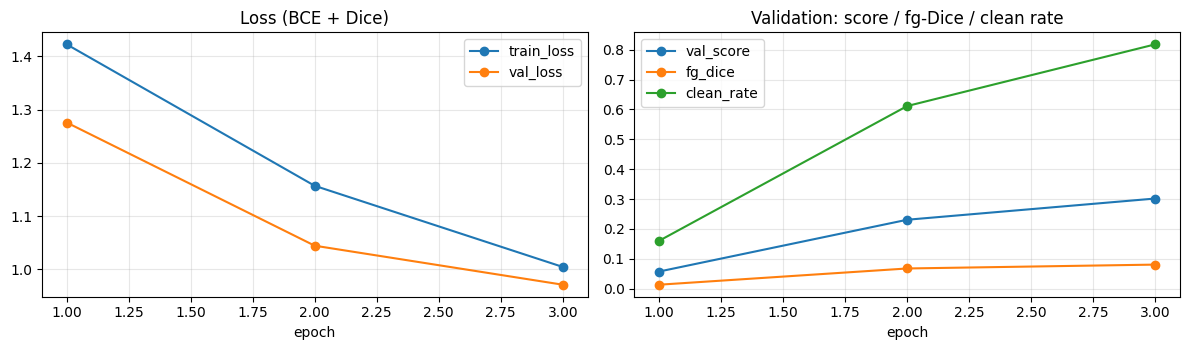

<All keys matched successfully>

In [11]:
hist = pd.DataFrame(history).set_index("epoch")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
hist[["train_loss", "val_loss"]].plot(ax=ax[0], marker="o", title="Loss (BCE + Dice)")
hist[["val_score", "fg_dice", "clean_rate"]].plot(ax=ax[1], marker="o", title="Validation: score / fg-Dice / clean rate")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
getattr(model, "module", model).load_state_dict(torch.load(CKPT, map_location=dev))   # restore best weights

## 7 · Post-processing: threshold, minimum area and flip-TTA
Raw probabilities are turned into masks with two knobs **per defect class**:

* **Probability threshold** — how confident a pixel must be.
* **Minimum area** — if a class' mask has fewer pixels than this, the whole mask is discarded. This kills tiny speckle predictions on clean images, which is exactly what the 30 % “false-positive / empty” part of the score punishes.

Both are tuned on the validation set to maximise the competition-style score (the objective is separable per class, so a simple grid search is exact). **Test-time augmentation** averages predictions over the original, horizontally- and vertically-flipped image, which smooths the probability maps.

In [12]:
@torch.no_grad()
def predict_probs(model, X_uint8, bs=64, tta=True):
    # returns sigmoid probabilities (N,4,H,W) as float16 on the GPU
    model.eval(); out = []
    for s in range(0, len(X_uint8), bs):
        x = prep(X_uint8[s:s + bs])
        with autocast():
            p = torch.sigmoid(model(x).float())
            if tta:
                p = p + torch.sigmoid(model(x.flip(3)).float()).flip(3) + torch.sigmoid(model(x.flip(2)).float()).flip(2)
                p = p / 3
        out.append(p.half())
    return torch.cat(out)

def apply_post(prob_c, thr, min_area):
    # prob_c (N,H,W) -> boolean masks; whole mask dropped if its area < min_area
    m = prob_c > thr
    area = m.flatten(1).sum(1)
    return m & (area >= min_area).view(-1, 1, 1)

val_probs = predict_probs(model, Xva, tta=True)
gt_sum = Yva.flatten(2).sum(2).numpy()                       # (N,4) true pixels per pair
Npos, Nneg = int((gt_sum > 0).sum()), int((gt_sum == 0).sum())
print("val pairs with defect:", Npos, "| without:", Nneg)

THRS  = np.round(np.arange(0.30, 0.86, 0.05), 2)
AREAS = [0, 50, 100, 200, 400, 800, 1200, 1600, 2400]
tuned = {}
for c, d in enumerate(DEFECTS):
    gt = Yva[:, c].to(dev).bool(); g = gt_sum[:, c]; pos = g > 0
    best = (-1, None)
    for thr in THRS:
        m = val_probs[:, c] > thr
        area = m.flatten(1).sum(1).cpu().numpy(); inter = (m & gt).flatten(1).sum(1).cpu().numpy()
        for ma in AREAS:
            keep = area >= ma; ps = np.where(keep, area, 0); it = np.where(keep, inter, 0)
            dice = 2 * it / (ps + g + 1e-9)
            obj = 0.7 * dice[pos].sum() / Npos + 0.3 * (ps[~pos] == 0).sum() / Nneg      # this class' share of the score
            if obj > best[0]: best = (obj, dict(thr=float(thr), min_area=int(ma)))
    tuned[d] = best[1]; print(f"{d}: {best[1]}")
json.dump(tuned, open(f"{WORK_DIR}/postproc.json", "w"), indent=2)

def val_stats(params):
    I, P = np.zeros((len(Xva), 4)), np.zeros((len(Xva), 4))
    for c, d in enumerate(DEFECTS):
        m = apply_post(val_probs[:, c], params[d]["thr"], params[d]["min_area"])
        I[:, c] = (m & Yva[:, c].to(dev).bool()).flatten(1).sum(1).cpu().numpy(); P[:, c] = m.flatten(1).sum(1).cpu().numpy()
    return I, P

default = {d: dict(thr=0.5, min_area=0) for d in DEFECTS}
I0, P0 = val_stats(default); s0, p0 = competition_score(I0, P0, gt_sum)
I, P = val_stats(tuned); s1, p1 = competition_score(I, P, gt_sum)
print(f"\nvalidation score   default (thr 0.5, no area filter): {s0:.4f}  (fg-dice {p0['fg_dice']:.3f})")
print(f"validation score   tuned post-processing + TTA      : {s1:.4f}  (fg-dice {p1['fg_dice']:.3f}, clean {p1['clean_rate']:.3f})")
print("Project cut-off: 0.65 ->", "PASS on validation" if s1 >= 0.65 else "below cut-off on validation (see notes at the end)")
log(dict(final_val_score=s1, final_fg_dice=p1["fg_dice"], final_clean_rate=p1["clean_rate"], default_val_score=s0))

val pairs with defect: 1441 | without: 7675
defect_a: {'thr': 0.3, 'min_area': 50}
defect_b: {'thr': 0.3, 'min_area': 0}
defect_c: {'thr': 0.3, 'min_area': 800}
defect_d: {'thr': 0.3, 'min_area': 800}

validation score   default (thr 0.5, no area filter): 0.3056  (fg-dice 0.074)
validation score   tuned post-processing + TTA      : 0.3370  (fg-dice 0.087, clean 0.921)
Project cut-off: 0.65 -> below cut-off on validation (see notes at the end)


## 8 · Error analysis (material for the report)

,val_pos,fg_dice,detected,dice_when_detected,false_alarm_rate,median_true_area
defect,,,,,,
defect_a,216,0.000,0.000,0.000,0.000,472
defect_b,63,0.000,0.000,0.000,0.000,630
defect_c,820,0.094,0.237,0.399,0.177,2333
defect_d,342,0.138,0.456,0.303,0.178,4910


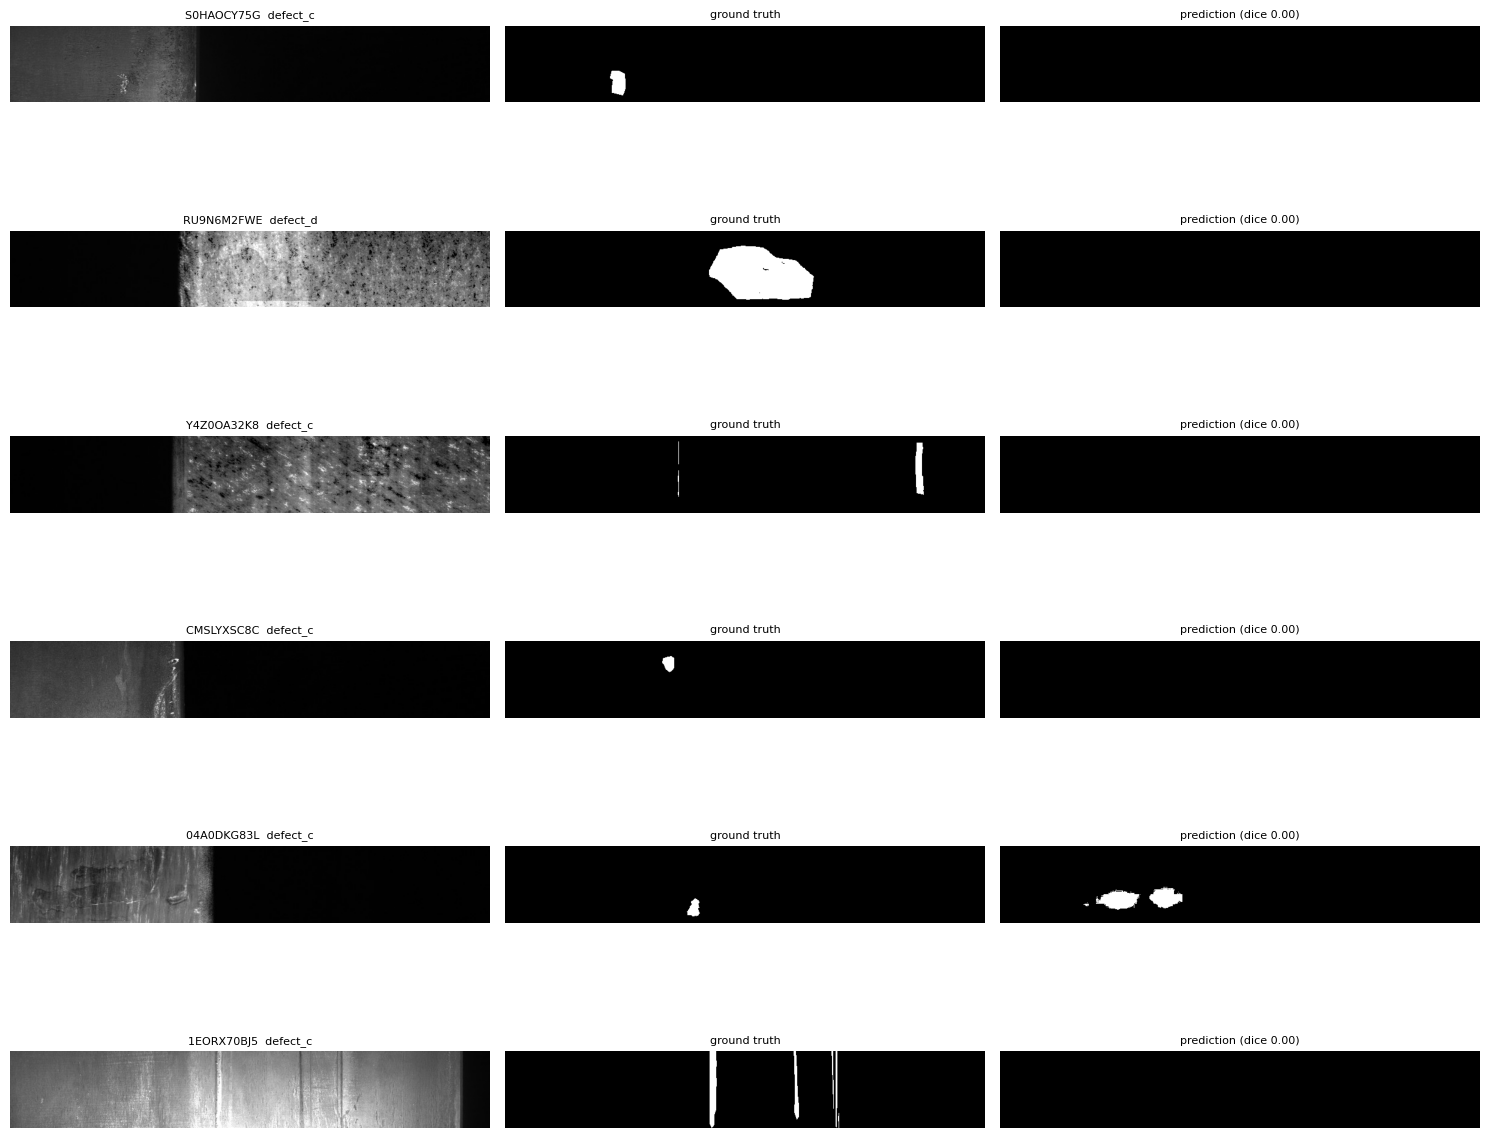

In [13]:
rows = []
for c, d in enumerate(DEFECTS):
    pos = gt_sum[:, c] > 0
    dice = 2 * I[pos, c] / (P[pos, c] + gt_sum[pos, c])
    rows.append(dict(defect=d, val_pos=int(pos.sum()), fg_dice=dice.mean(),
                     detected=(P[pos, c] > 0).mean(),                          # recall of "a defect is present"
                     dice_when_detected=dice[P[pos, c] > 0].mean() if (P[pos, c] > 0).any() else 0.0,
                     false_alarm_rate=(P[~pos, c] > 0).mean(),
                     median_true_area=int(np.median(gt_sum[pos, c]))))
analysis = pd.DataFrame(rows).set_index("defect"); display(analysis.round(3))

# worst-case examples: lowest-Dice positive pairs
pair_dice = np.where(gt_sum > 0, 2 * I / (P + gt_sum + 1e-9), np.inf)
worst = np.dstack(np.unravel_index(np.argsort(pair_dice.ravel())[:6], pair_dice.shape))[0]
fig, ax = plt.subplots(len(worst), 3, figsize=(15, 2.2 * len(worst)))
for r, (i, c) in enumerate(worst):
    img = Xva[i].numpy().transpose(1, 2, 0)
    pm = apply_post(val_probs[i:i + 1, c], tuned[DEFECTS[c]]["thr"], tuned[DEFECTS[c]]["min_area"])[0].cpu().numpy()
    ax[r, 0].imshow(img); ax[r, 0].set_title(f"{val_tab.image_id[i]}  {DEFECTS[c]}", fontsize=8)
    ax[r, 1].imshow(Yva[i, c].numpy(), cmap="gray"); ax[r, 1].set_title("ground truth", fontsize=8)
    ax[r, 2].imshow(pm, cmap="gray"); ax[r, 2].set_title(f"prediction (dice {pair_dice[i, c]:.2f})", fontsize=8)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

## 9 · Final predictions and `submission.csv`
The 3000 test images are processed in chunks (to keep RAM low), predicted with flip-TTA, post-processed with the tuned per-class parameters, RLE-encoded, and written in the **same row order and columns as `sample_submission.csv`**. Empty predictions are written as a single space `" "`, exactly as in the sample file.

In [14]:
sample = pd.read_csv(SAMPLE_SUB, keep_default_na=False)
test_ids = sample.image_id.drop_duplicates().tolist()
missing = [i for i in test_ids if i not in TEST_PATHS]; assert not missing, f"{len(missing)} test images not found"
print("test images:", len(test_ids), "| rows expected:", len(sample))

@torch.no_grad()
def predict_test(ids, chunk=256):
    res = {}
    for s in range(0, len(ids), chunk):
        part = ids[s:s + chunk]
        with ThreadPoolExecutor(8) as ex:
            X = torch.from_numpy(np.stack(list(ex.map(lambda i: read_rgb(TEST_PATHS[i]).transpose(2, 0, 1), part))))
        probs = predict_probs(model, X, tta=True)
        for c, d in enumerate(DEFECTS):
            m = apply_post(probs[:, c], tuned[d]["thr"], tuned[d]["min_area"]).cpu().numpy().astype(np.uint8)
            for j, iid in enumerate(part):
                res[(iid, d)] = rle_encode(m[j]) or " "
        print(f"  {min(s + chunk, len(ids))}/{len(ids)}", end="\r")
    return res

t0 = time.time(); preds = predict_test(test_ids); print(f"\npredicted in {time.time()-t0:.0f}s")

sub = sample.copy()
sub["mask_rle"] = [preds[(i, d)] for i, d in zip(sub.image_id, sub.defect_type)]
sub.to_csv(f"{WORK_DIR}/submission.csv", index=False, quoting=csv.QUOTE_ALL)

test images: 3000 | rows expected: 12000
  3000/3000
predicted in 2108s


**Format validation** — checks that the file matches the sample exactly and that the predictions look statistically plausible.

In [15]:
chk = pd.read_csv(f"{WORK_DIR}/submission.csv", keep_default_na=False)
assert list(chk.columns) == list(sample.columns) == ["ID", "image_id", "defect_type", "mask_rle"]
assert len(chk) == len(sample) == 12000
assert (chk.ID.values == sample.ID.values).all() and (chk.image_id.values == sample.image_id.values).all()
assert (chk.defect_type.values == sample.defect_type.values).all()
assert chk.mask_rle.map(lambda s: isinstance(s, str)).all()

nonempty_pred = chk.mask_rle.str.strip() != ""
for r in chk[nonempty_pred].mask_rle.sample(min(50, nonempty_pred.sum()), random_state=0):        # RLE must be decodable & in range
    m = rle_decode(r); assert m.shape == (H, W) and m.sum() == sum(map(int, r.split()[1::2]))
print("format OK")
print(f"predicted non-empty pairs: {nonempty_pred.mean():.3f}   (train set: {df.has_defect.mean():.3f})")
display(chk.assign(has=nonempty_pred).groupby("defect_type").has.mean().round(3).to_frame("predicted_positive_rate")
        .join(df.groupby("defect_type").has_defect.mean().round(3).rename("train_rate")))
display(chk.head(8))
if RUN is not None: RUN.finish()

format OK
predicted non-empty pairs: 0.104   (train set: 0.158)


,predicted_positive_rate,train_rate
defect_type,,
defect_a,0.000,0.095
defect_b,0.000,0.027
defect_c,0.181,0.360
defect_d,0.235,0.150


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


## 10 · Notes and next steps

**How to run:** Kaggle → *GPU T4 ×2* → add the competition data → *Run all*. The notebook writes `submission.csv`, `unet_scratch_best.pt`, `postproc.json` and `split.csv` to `/kaggle/working`. Set `CFG["debug"] = True` first for a 1-minute smoke test.

**If the validation score is below 0.65**, the cheapest levers, in order: (1) raise `epochs` to 40–50 (the OneCycle schedule adapts automatically); (2) raise `base` to 32; (3) train on the full width (`crop_w = 800`) for the last few epochs; (4) average several checkpoints / seeds before tuning the thresholds. A pretrained encoder (Model 2) usually gives the largest single jump on this kind of data.

**Project-guideline checklist**

| Requirement | Status |
|---|---|
| Model built from scratch | ✅ this notebook (residual U-Net, random init) |
| Pretrained model | ⬜ Model 2 — U-Net with an ImageNet encoder (reuse `split.csv`, the loss and the post-processing code above) |
| Third model of choice | ⬜ Model 3 — e.g. DeepLabV3+ or a different loss/resolution setup |
| ≥ 3 W&B runs compared on common metrics | ⬜ this run logs `val_score`, `val_fg_dice`, `val_clean_rate` — log the same keys in Models 2 and 3 |
| GitHub history over > 3 weeks, modular code, `requirements.txt` | ⬜ commit this notebook and split it into `data.py / model.py / train.py / infer.py` |

**Security reminder:** never paste GitHub / W&B tokens into notebooks, READMEs or Google Docs. Use Kaggle Secrets (as above) and environment variables.